In [175]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

from scikeras.wrappers import KerasRegressor

from sklearn.metrics import mean_absolute_error

In [176]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [177]:
# Fix random state
random_state = 42

In [178]:
apokasc = pd.read_csv('apokasc3_ages_final.csv')

print (f'apokasc contains {len(apokasc)} stars')
apokasc.head(2)

apokasc contains 11996 stars


,fe_h,radial_velocity,APOKASC3_CAT_AGE,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,phot_g_mean_mag,...,phot_rp_mean_mag,ra,dec,source_id,age_rgb,age_rcagb,U_lsr,V_lsr,W_lsr,P_gal
0,0.087277,-58.478256,RGB,0.243932,0.019925,-3.338659,0.025822,-6.593166,0.025052,15.0817,...,14.3722,286.335457,46.917831,2130600994852949504,9.5078,9.5078,-137.595959,-77.334548,2.611390,3.8
1,-0.161410,-48.234500,RGB,0.416620,0.011684,-0.358099,0.015070,-0.587580,0.015026,13.7617,...,13.0871,286.365656,46.981289,2130601682047747072,7.1350,7.1350,-8.538786,-34.790795,-5.765871,98.0


# Here we focus on getting Fe from no abundance

In [179]:
apokasc_fe = apokasc[['fe_h']]
columns_for_Fe_age = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', 'age_rcagb', ]

apokasc = apokasc[columns_for_Fe_age]
apokasc.head(2)

,radial_velocity,V_lsr,U_lsr,W_lsr,P_gal,age_rcagb
0,-58.478256,-77.334548,-137.595959,2.611390,3.8,9.5078
1,-48.234500,-34.790795,-8.538786,-5.765871,98.0,7.1350


In [180]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    #X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    return X

apokasc = fit_trasform(apokasc)

In [181]:
apokasc = apokasc[apokasc.age_rcagb < 13.5]  # Filter out ages greater than 13.5 Gyr

In [182]:
apokasc.describe()

,radial_velocity,V_lsr,U_lsr,W_lsr,P_gal,age_rcagb,VW_lsr,UW_lsr,UV_lsr,UVW_lsr
count,11609.000000,11609.000000,11609.000000,11609.000000,11609.000000,11609.000000,11609.000000,11609.000000,11609.000000,11609.000000
mean,-25.576121,-23.980094,-56.128832,-1.664885,74.885847,5.109881,40.247590,70.563198,76.597509,81.229371
std,36.401656,38.908195,59.418637,26.467354,34.076205,2.940469,34.237800,49.040704,53.875317,53.616671
min,-588.899960,-546.743828,-726.154953,-213.918497,0.000000,0.094000,0.145268,0.327979,0.705607,2.058958
25%,-42.852135,-41.106112,-89.637542,-15.704231,63.400000,2.749200,19.168542,35.142639,39.980756,44.565010
50%,-20.387403,-19.049842,-52.740740,-1.275836,94.000000,4.716800,32.268901,60.605270,65.223696,69.521204
75%,-2.516284,1.120082,-18.452642,12.554013,98.000000,7.135400,50.921049,95.479815,100.611542,104.961798
max,62.003800,87.678027,367.617920,331.310135,99.200000,13.453600,547.017539,726.754939,731.565974,732.161525


# Training a model to predict the age of stars based on their kinematics

### Spliting data into Trianing and Testing sets

In [183]:
apokasc_train_full, apokasc_test = train_test_split(apokasc, test_size=0.1, random_state=random_state)
X_apokasc_train = apokasc_train_full.drop(columns=['age_rcagb'])
y_apokasc_train = apokasc_train_full['age_rcagb']

X_apokasc_test = apokasc_test.drop(columns=['age_rcagb'])
y_apokasc_test = apokasc_test['age_rcagb']


In [184]:
def feature_target_correlation(df, target):
    corr = df.corr(numeric_only=True)[target].drop(target).sort_values(key=abs, ascending=False)
    return corr
correlations = feature_target_correlation(df=X_apokasc_train.assign(fe_h=y_apokasc_train), target='fe_h')
correlations


VW_lsr             0.271261
P_gal             -0.253698
radial_velocity   -0.244838
V_lsr             -0.234257
UVW_lsr            0.157500
UV_lsr             0.129495
UW_lsr             0.098640
W_lsr             -0.031297
U_lsr              0.008829
Name: fe_h, dtype: float64

In [185]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)
catr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)




model_names = {
    'xgbr': xgbr,
    #'rfr': rfr,
    #'extr': extr,  
    #'svr': svr,
    #'lr': lr,
    'lgbr': lgbr,
    #'catr': catr,
    #'voting_r': voting_r 
}


In [186]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [187]:
baseline_results = model_test_CV_models(X_apokasc_train, y_apokasc_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr


xgbr done in 0.96s → MAE: 2.275 ± 0.023

Scoring model: lgbr
lgbr done in 0.73s → MAE: 2.199 ± 0.014

xgbr     | MAE: 2.275 ± 0.023
lgbr     | MAE: 2.199 ± 0.014


In [188]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [189]:
# Evaluate on Apogee test
results_apogee = evaluate_on_test_data(
    X_apokasc_test, y_apokasc_test,
    test_df=apokasc_test,
    target='age_rcagb',
    models=model_names,
    test_name='Apokasc'
)


Training and evaluating xgbr on Apokasc
xgbr | Apokasc MAE: 0.256 (mean baseline: 2.439)

Training and evaluating lgbr on Apokasc
lgbr | Apokasc MAE: 1.051 (mean baseline: 2.439)



In [190]:
def plot_residuals_vs_features(X, y_true, y_pred, feature_names=None, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs each feature in X.

    Parameters:
        X: DataFrame or array of features.
        y_true: True target values.
        y_pred: Predicted target values.
        feature_names: Optional list of feature names.
        model_name: For labeling plots.
        sample_name: Dataset name for titles.
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    if isinstance(X, np.ndarray):
        X = pd.DataFrame(X, columns=feature_names if feature_names else [f'feature_{i}' for i in range(X.shape[1])])

    residuals =  np.array(y_pred)

    num_features = X.shape[1]
    ncols = 3
    nrows = int(np.ceil(num_features / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows))

    for idx, col in enumerate(X.columns):
        ax = axes.flatten()[idx]
        ax.scatter(X[col], residuals, alpha=0.6, s=20)
        ax.axhline(0, color='gray', linestyle='--')
        ax.set_xlabel(col)
        ax.set_ylabel('Residual')
        ax.set_title(f'{col} vs Residual')

    for j in range(idx + 1, nrows * ncols):
        fig.delaxes(axes.flatten()[j])  # Remove empty subplots

    fig.suptitle(f'{model_name} Residuals vs Features ({sample_name})', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [196]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    #residuals_model = y_true - y_pred
    residuals_model =  y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    #plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


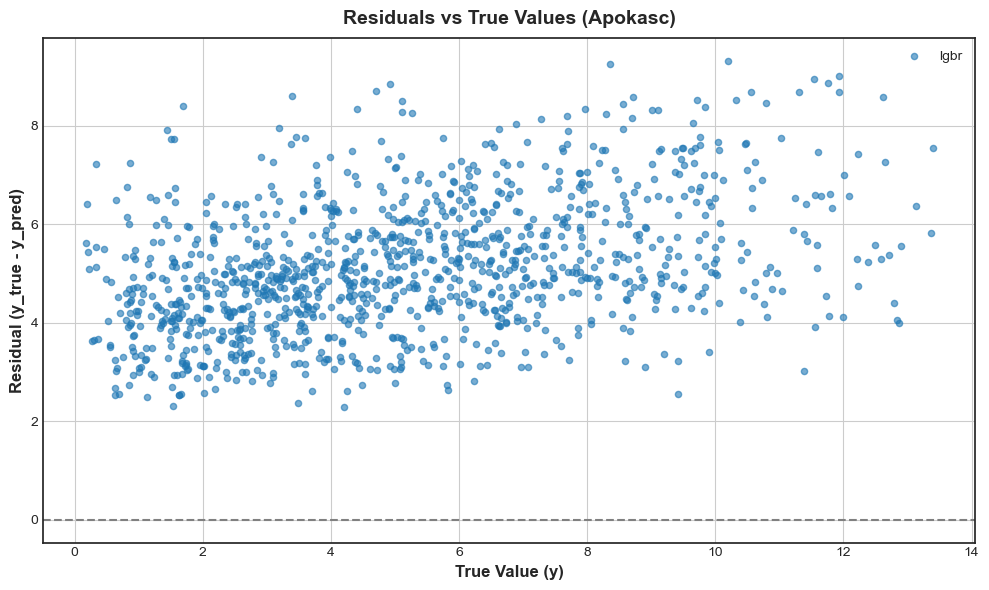

In [198]:
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
model.fit(X_apokasc_train, y_apokasc_train)

y_pred_apokasc = model.predict(X_apokasc_test)
plot_residuals_vs_true(y_apokasc_test, y_pred_apokasc, model_name=best_model_name, sample_name='Apokasc')


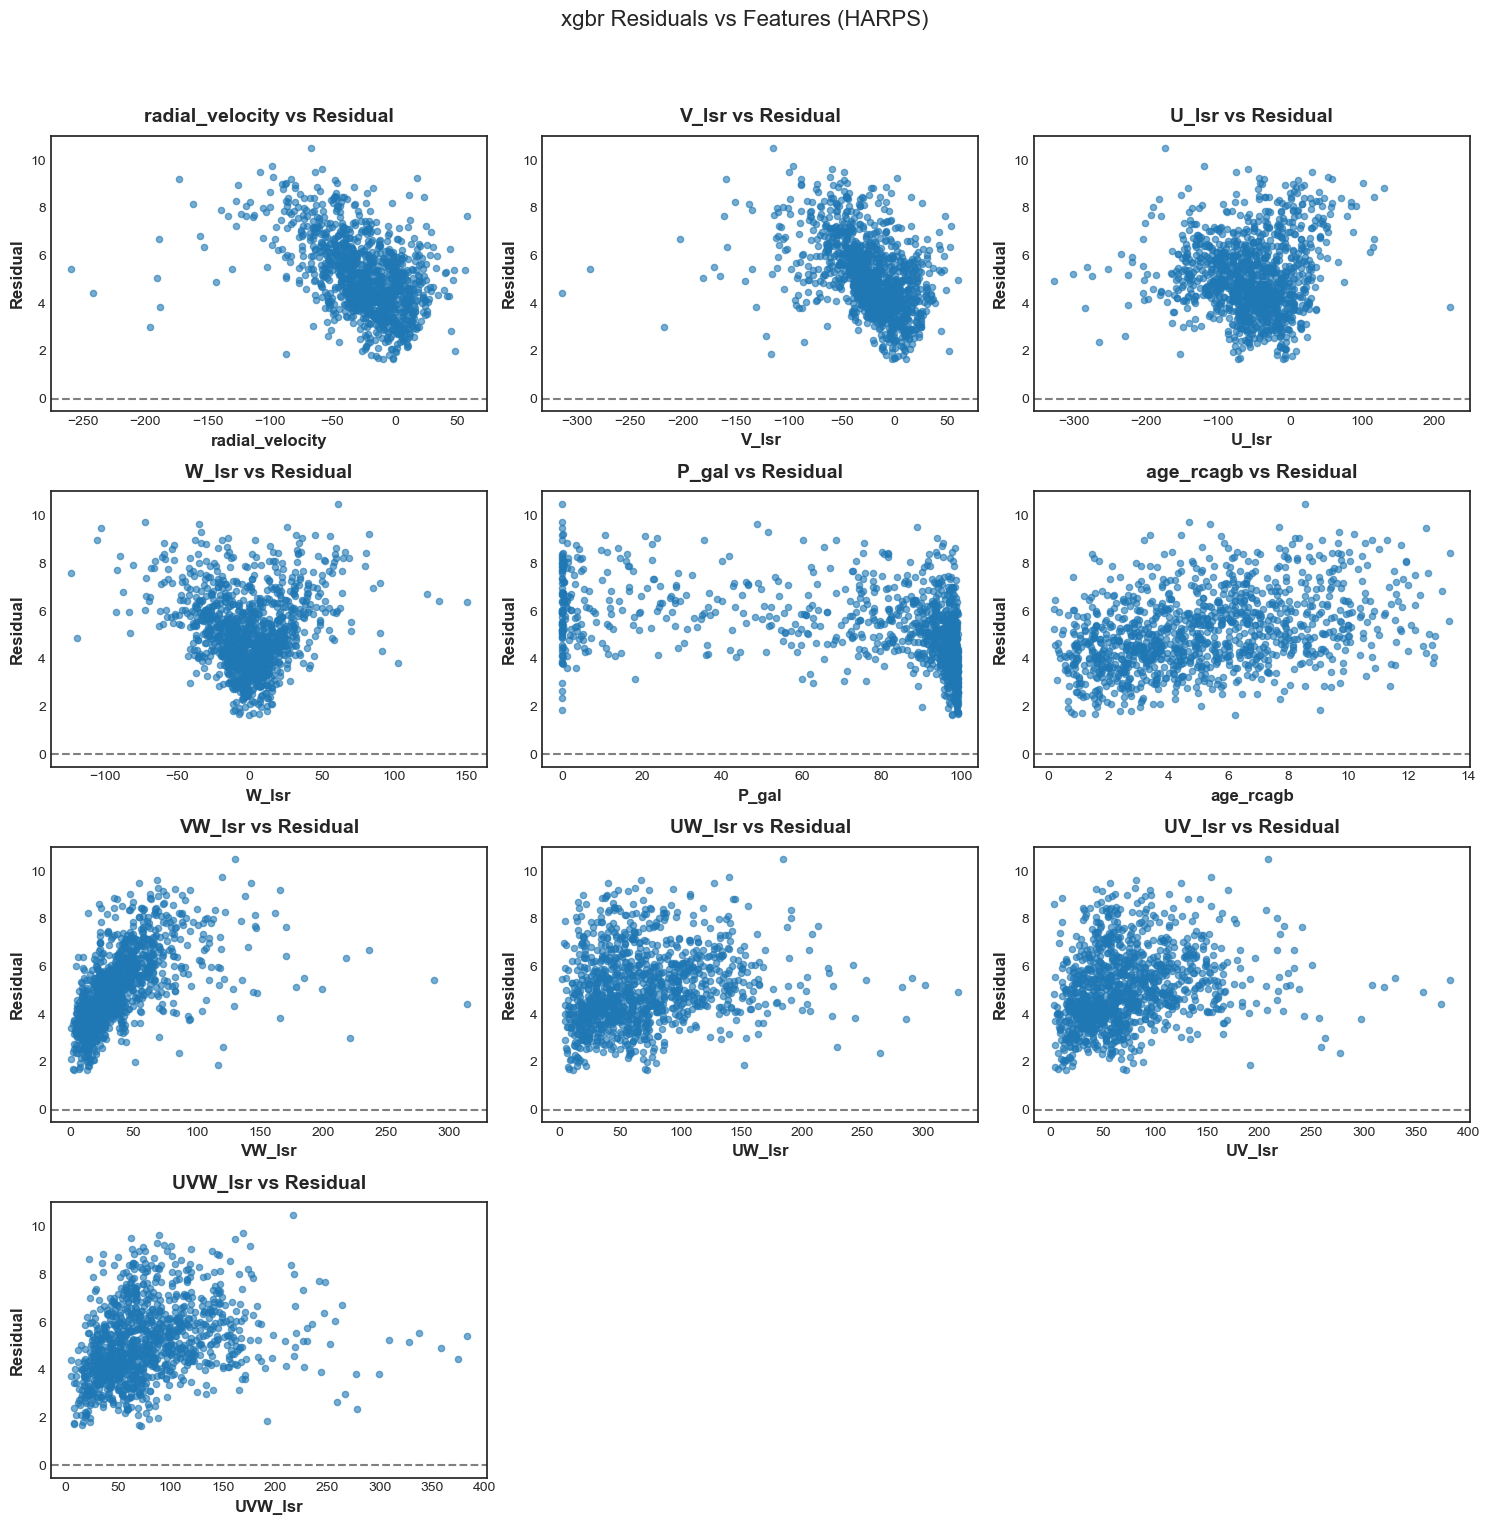

In [193]:
plot_residuals_vs_features(apokasc_test, y_apokasc_test, y_pred_apokasc, model_name='xgbr', sample_name='HARPS')